# Проект для «Викишоп»

Интернет-магазин «Викишоп» запускает новый сервис. Теперь пользователи могут редактировать и дополнять описания товаров, как в вики-сообществах. То есть клиенты предлагают свои правки и комментируют изменения других. Магазину нужен инструмент, который будет искать токсичные комментарии и отправлять их на модерацию. 

Обучите модель классифицировать комментарии на позитивные и негативные. В вашем распоряжении набор данных с разметкой о токсичности правок.

Постройте модель со значением метрики качества *F1* не меньше 0.75. 

**Инструкция по выполнению проекта**

1. Загрузите и подготовьте данные.
2. Обучите разные модели. 
3. Сделайте выводы.

Для выполнения проекта применять *BERT* необязательно, но вы можете попробовать.

**Описание данных**

Данные находятся в файле `toxic_comments.csv`. Столбец *text* в нём содержит текст комментария, а *toxic* — целевой признак.

## Подготовка

In [1]:
!pip install phik -q

In [2]:
import re

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import phik
import seaborn as sns
from nltk.corpus import stopwords as nltk_stopwords
from nltk.stem import WordNetLemmatizer
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from tqdm.notebook import tqdm

RANDOM_STATE = 42

nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('stopwords')

[nltk_data] Downloading package wordnet to /home/jovyan/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/jovyan/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package stopwords to /home/jovyan/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

#### 1. Загрузка данных

In [3]:
try:
    df = pd.read_csv('https://code.s3.yandex.net/datasets/toxic_comments.csv')
except FileNotFoundError:
    df = pd.read_csv('https://code.s3.yandex.net/datasets/toxic_comments.csv')

#### 2. Первичный осмотр

In [4]:
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

display(df.head())
df.info()

,text,toxic
0,Explanation\nWhy the edits made under my usern...,0
1,D'aww! He matches this background colour I'm s...,0
2,"Hey man, I'm really not trying to edit war. It...",0
3,"""\nMore\nI can't make any real suggestions on ...",0
4,"You, sir, are my hero. Any chance you remember...",0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159292 entries, 0 to 159291
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   text    159292 non-null  object
 1   toxic   159292 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ MB


In [5]:
num_cols = ['len_chars', 'len_words', 'caps_share']
names = {
    'len_chars': 'Длина, символов',
    'len_words': 'Длина, слов',
    'caps_share': 'Доля заглавных букв'
}

df['len_chars'] = df['text'].str.len()
df['len_words'] = df['text'].str.split().str.len()
letters = df['text'].str.count(r'[A-Za-z]')
df['caps_share'] = (df['text'].str.count(r'[A-Z]') / letters.replace(0, np.nan)).fillna(0)

df.describe()

,toxic,len_chars,len_words,caps_share
count,159292.000000,159292.000000,159292.000000,159292.000000
mean,0.101612,393.691303,67.213545,0.069470
std,0.302139,590.111825,99.133908,0.124819
min,0.000000,5.000000,1.000000,0.000000
25%,0.000000,95.000000,17.000000,0.026706
50%,0.000000,205.000000,36.000000,0.041420
75%,0.000000,435.000000,75.000000,0.065041
max,1.000000,5000.000000,1411.000000,1.000000


#### 3. Дубликаты и пропуски

In [6]:
print('Пропуски по столбцам:')
print(df.isna().sum())
print()
print('Полных дубликатов:', df.duplicated().sum())
print('Повторяющихся текстов:', df['text'].duplicated().sum())
print('Пустых текстов:', (df['text'].str.strip() == '').sum())

Пропуски по столбцам:
text          0
toxic         0
len_chars     0
len_words     0
caps_share    0
dtype: int64

Полных дубликатов: 0
Повторяющихся текстов: 0
Пустых текстов: 0


#### 4. Фильтрация данных

Для задачи нужен весь датасет: каждый комментарий — отдельный объект для классификации, срез не требуется. Если на шаге 3 найдутся дубликаты или пустые тексты, удалим их.

In [7]:
df = df.drop_duplicates(subset='text')
df = df[df['text'].str.strip() != ''].reset_index(drop=True)
print('Размер после очистки:', df.shape)

Размер после очистки: (159292, 5)


#### 5. Распределения признаков

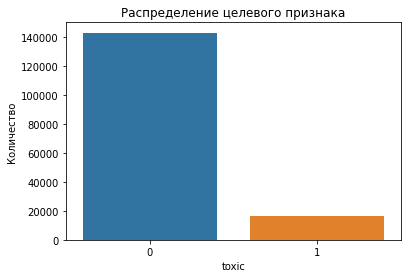

0    0.898388
1    0.101612
Name: toxic, dtype: float64


In [8]:
sns.countplot(x='toxic', data=df)
plt.title('Распределение целевого признака')
plt.xlabel('toxic')
plt.ylabel('Количество')
plt.show()

print(df['toxic'].value_counts(normalize=True))

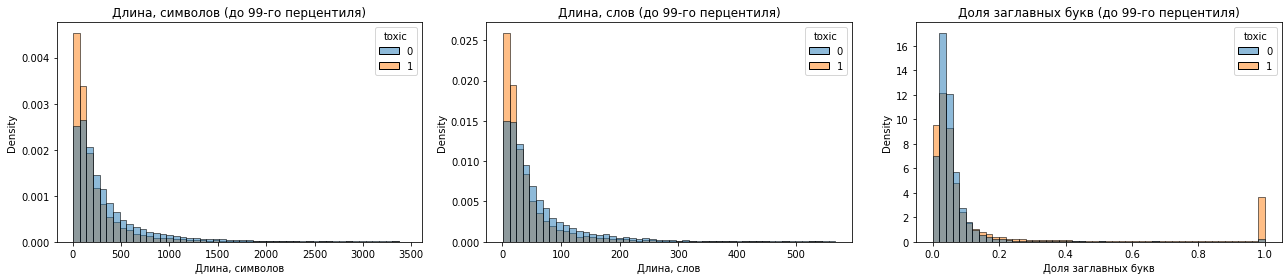

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    upper = df[col].quantile(0.99)
    sns.histplot(data=df[df[col] <= upper], x=col, hue='toxic', bins=50,
                 stat='density', common_norm=False, ax=ax)
    ax.set_title(f'{names[col]} (до 99-го перцентиля)')
    ax.set_xlabel(names[col])
plt.tight_layout()
plt.show()

#### 6. Боксплоты

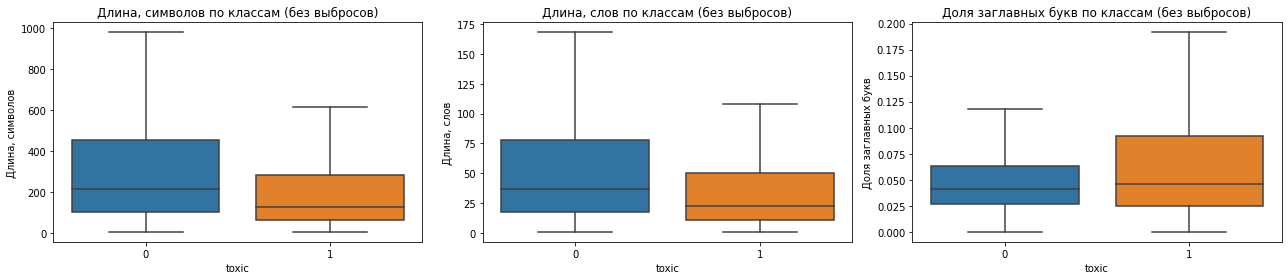

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x='toxic', y=col, showfliers=False, ax=ax)
    ax.set_title(f'{names[col]} по классам (без выбросов)')
    ax.set_ylabel(names[col])
plt.tight_layout()
plt.show()

#### 7. Проверка на нормальность и статистические тесты

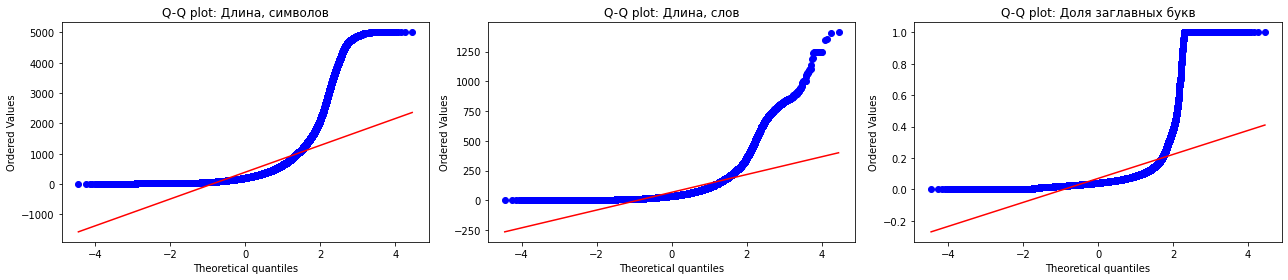

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    stats.probplot(df[col], dist='norm', plot=ax)
    ax.set_title(f'Q-Q plot: {names[col]}')
plt.tight_layout()
plt.show()

In [12]:
for col in num_cols:
    toxic_vals = df.loc[df['toxic'] == 1, col]
    normal_vals = df.loc[df['toxic'] == 0, col]
    p_value = stats.mannwhitneyu(toxic_vals, normal_vals).pvalue
    print(f'{names[col]}: медиана токсичных = {toxic_vals.median():.3f}, '
          f'нетоксичных = {normal_vals.median():.3f}, p-value = {p_value:.2e}')

Длина, символов: медиана токсичных = 128.000, нетоксичных = 216.000, p-value = 0.00e+00
Длина, слов: медиана токсичных = 23.000, нетоксичных = 37.000, p-value = 0.00e+00
Доля заглавных букв: медиана токсичных = 0.046, нетоксичных = 0.041, p-value = 4.28e-70


Распределения не нормальные: сильная правая асимметрия, точки на Q-Q плотах далеко отходят от прямой. Поэтому для сравнения классов используем непараметрический тест Манна–Уитни, а не t-тест.

#### 8. Обработка пропусков

Пропусков в данных нет, заполнять нечего. Вопрос утечки данных решён на этапе обучения: TF-IDF стоит внутри пайплайна вместе с моделью, поэтому словарь и веса IDF считаются только по обучающей части (и по обучающим фолдам при кросс-валидации).

#### 9. Корреляции

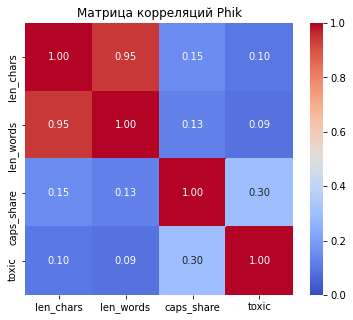

In [13]:
phik_corr = df[num_cols + ['toxic']].phik_matrix(interval_cols=num_cols)

plt.figure(figsize=(6, 5))
sns.heatmap(phik_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=0, vmax=1)
plt.title('Матрица корреляций Phik')
plt.show()

Используем коэффициент Phik: он работает и с непрерывными, и с категориальными признаками (у нас бинарный целевой признак `toxic`), улавливает нелинейные зависимости и не требует нормальности распределений. Длина в символах и длина в словах ожидаемо сильно связаны (мультиколлинеарность). Но это вспомогательные признаки: модель обучается на векторах TF-IDF, поэтому мультиколлинеарность на результат не влияет.

#### 10. Вывод по EDA

Данные загружены. Тексты на английском языке. Служебный столбец-индекс удалён. Классы несбалансированы: токсичных комментариев около 10%. Это учтём при обучении с помощью class_weight='balanced' и стратифицированного разбиения.

**Вывод по EDA**

- **Данные.** Датасет содержит 159 292 англоязычных комментария и 2 столбца: `text` (текст комментария) и `toxic` (целевой признак). Пропусков, дубликатов и пустых текстов нет, поэтому фильтрация и заполнение пропусков не потребовались, все объекты сохранены.
- **Дисбаланс классов.** Токсичных комментариев около 10% (16 тыс. против 143 тыс. нетоксичных). Поэтому при разбиении используем стратификацию, при обучении задаём `class_weight='balanced'`, а качество оцениваем по F1, а не по accuracy: модель, всегда предсказывающая «0», получила бы accuracy около 0.9, но была бы бесполезна.
- **Длина комментариев.** Распределения длины сильно скошены вправо: медиана 205 символов (36 слов), а максимум 5000 символов (1411 слов). Максимум ровно в 5000 символов похож на ограничение платформы. Токсичные комментарии заметно короче: медиана 128 символов против 216 у нетоксичных (23 слова против 37).
- **Доля заглавных букв.** У токсичных комментариев она выше, особенно в «хвосте»: на гистограмме у токсичного класса виден отдельный пик в значении 1.0, то есть комментарии, целиком написанные КАПСОМ. Это типичная манера «кричать» на собеседника.
- **Нормальность и тесты.** Q-Q плоты показывают, что ни один из вспомогательных признаков не распределён нормально. Тест Манна–Уитни подтвердил статистически значимые различия между классами по всем трём признакам (p-value < 0.001).
- **Корреляции (Phik).** Длина в символах и длина в словах почти дублируют друг друга (0.95), это мультиколлинеарность. Связь с целевым признаком сильнее всего у доли заглавных букв (0.30), у длины она слабая (0.09–0.10). Вспомогательные признаки в обучении не участвуют: модель строится на TF-IDF, поэтому мультиколлинеарность на результат не влияет.

**Итог:** данные чистые и готовы к обработке. Главные особенности — сильный дисбаланс классов, который учтён при обучении, и стилистические отличия токсичных комментариев: они короче, и в них чаще встречается капс.

In [14]:
lemmatizer = WordNetLemmatizer()

def clear_and_lemmatize(text):
    text = re.sub(r'[^a-zA-Z ]', ' ', text.lower())
    return ' '.join(lemmatizer.lemmatize(word) for word in text.split())

tqdm.pandas()
df['lemm_text'] = df['text'].progress_apply(clear_and_lemmatize)

df[['text', 'lemm_text']].head()

  0%|          | 0/159292 [00:00<?, ?it/s]

,text,lemm_text
0,Explanation\nWhy the edits made under my usern...,explanation why the edits made under my userna...
1,D'aww! He matches this background colour I'm s...,d aww he match this background colour i m seem...
2,"Hey man, I'm really not trying to edit war. It...",hey man i m really not trying to edit war it s...
3,"""\nMore\nI can't make any real suggestions on ...",more i can t make any real suggestion on impro...
4,"You, sir, are my hero. Any chance you remember...",you sir are my hero any chance you remember wh...


In [15]:
features = df['lemm_text']
target = df['toxic']

features_train, features_test, target_train, target_test = train_test_split(
    features, target, test_size=0.2, random_state=RANDOM_STATE, stratify=target)

print('Обучающая:', features_train.shape)
print('Тестовая:', features_test.shape)

Обучающая: (127433,)
Тестовая: (31859,)


Тексты приведены к нижнему регистру, очищены от всего, кроме латинских букв, и лемматизированы. Данные разделены на обучающую (80%) и тестовую (20%) выборки со стратификацией по целевому признаку.

## Обучение

TF-IDF и модель объединены в пайплайн. Так при кросс-валидации векторизатор обучается только на тренировочных фолдах, и утечки данных нет. Гиперпараметры подбираются через GridSearchCV по метрике F1. Рассматриваются две модели: логистическая регрессия и линейный SVM.

In [16]:
stop_words = list(nltk_stopwords.words('english'))

def search_model(model, param_grid):
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(stop_words=stop_words)),
        ('model', model)
    ])
    grid = GridSearchCV(pipeline, param_grid, scoring='f1', cv=3)
    grid.fit(features_train, target_train)
    print('Лучшие параметры:', grid.best_params_)
    print('F1 на кросс-валидации:', round(grid.best_score_, 4))
    return grid

In [17]:
grid_lr = search_model(
    LogisticRegression(class_weight='balanced', solver='liblinear',
                       random_state=RANDOM_STATE),
    {'model__C': [1, 5, 10]}
)

Лучшие параметры: {'model__C': 5}
F1 на кросс-валидации: 0.7602


In [18]:
grid_svc = search_model(
    LinearSVC(class_weight='balanced', random_state=RANDOM_STATE),
    {'model__C': [0.1, 0.5, 1]}
)

Лучшие параметры: {'model__C': 0.5}
F1 на кросс-валидации: 0.7562


In [19]:
results = pd.DataFrame({
    'Модель': ['LogisticRegression', 'LinearSVC'],
    'F1 (кросс-валидация)': [grid_lr.best_score_, grid_svc.best_score_]
}).sort_values('F1 (кросс-валидация)', ascending=False)

results

,Модель,F1 (кросс-валидация)
0,LogisticRegression,0.760172
1,LinearSVC,0.756217


In [20]:
best_grid = grid_lr if grid_lr.best_score_ >= grid_svc.best_score_ else grid_svc

predictions = best_grid.predict(features_test)
print('Лучшая модель:', best_grid.best_estimator_.named_steps['model'])
print('F1 на тестовой выборке:', round(f1_score(target_test, predictions), 4))

Лучшая модель: LogisticRegression(C=5, class_weight='balanced', random_state=42,
                   solver='liblinear')
F1 на тестовой выборке: 0.7585


## Выводы

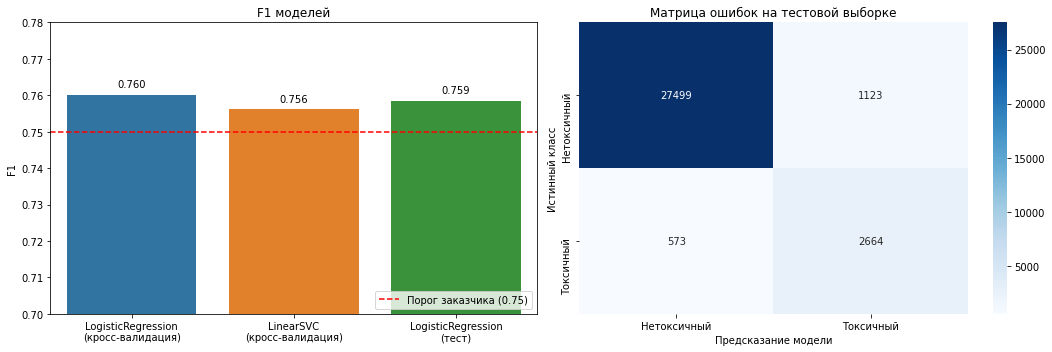

In [21]:
f1_test = f1_score(target_test, predictions)

scores = pd.DataFrame({
    'Модель': ['LogisticRegression\n(кросс-валидация)',
               'LinearSVC\n(кросс-валидация)',
               'LogisticRegression\n(тест)'],
    'F1': [grid_lr.best_score_, grid_svc.best_score_, f1_test]
})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# сравнение F1 с порогом заказчика
sns.barplot(data=scores, x='Модель', y='F1', ax=axes[0])
axes[0].axhline(0.75, color='red', linestyle='--', label='Порог заказчика (0.75)')
for i, value in enumerate(scores['F1']):
    axes[0].text(i, value + 0.002, f'{value:.3f}', ha='center')
axes[0].set_ylim(0.70, 0.78)
axes[0].set_title('F1 моделей')
axes[0].set_xlabel('')
axes[0].legend(loc='lower right')

# матрица ошибок лучшей модели на тесте
cm = confusion_matrix(target_test, predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Нетоксичный', 'Токсичный'],
            yticklabels=['Нетоксичный', 'Токсичный'])
axes[1].set_title('Матрица ошибок на тестовой выборке')
axes[1].set_xlabel('Предсказание модели')
axes[1].set_ylabel('Истинный класс')

plt.tight_layout()
plt.show()

**Общий вывод**

Задача: построить модель, которая отправляет токсичные комментарии на модерацию, с метрикой F1 не ниже 0.75.

**1. Подготовка данных.**
- Проведён EDA: пропусков и дубликатов нет. Выявлен дисбаланс классов (≈10% токсичных). Токсичные комментарии в среднем короче и чаще написаны капсом.
- Тексты приведены к нижнему регистру, очищены от всего, кроме латинских букв, и лемматизированы (WordNetLemmatizer).
- Данные разделены на обучающую и тестовую выборки в соотношении 80:20 со стратификацией.

**2. Обучение.**
- Векторизация TF-IDF с удалением английских стоп-слов объединена с моделью в пайплайн. Так при кросс-валидации TF-IDF обучается только на тренировочных фолдах, и утечки данных нет.
- Дисбаланс классов учтён параметром `class_weight='balanced'`.
- Гиперпараметры подобраны через GridSearchCV (3 фолда, метрика F1):

| Модель | Лучший C | F1 (кросс-валидация) |
|---|---|---|
| LogisticRegression | 5 | 0.760 |
| LinearSVC | 0.5 | 0.756 |

**3. Тестирование.**
Лучшая модель по кросс-валидации — **логистическая регрессия (C = 5)**. На тестовой выборке она показала **F1 = 0.7585**. Результат близок к значению на кросс-валидации, переобучения нет, и требование заказчика (F1 ≥ 0.75) выполнено.

**Рекомендация.** Логистическую регрессию на TF-IDF можно использовать для автоматической отправки комментариев на модерацию. Модель быстро обучается и предсказывает, не требует GPU и легко интерпретируется по весам слов. Если в будущем понадобится более высокое качество, можно попробовать биграммы в TF-IDF, подбор порога классификации или модели на основе BERT, но они потребуют больше вычислительных ресурсов.